In [15]:
import torch

print("torch:", torch.__version__)
print("cuda runtime:", torch.version.cuda)
print("cuda available:", torch.cuda.is_available())
print("archs:", torch.cuda.get_arch_list())

if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))

torch: 2.12.0.dev20260319+cu128
cuda runtime: 12.8
cuda available: True
archs: ['sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']
gpu: NVIDIA GeForce RTX 5060 Laptop GPU


## 1. Imports

In [16]:
from pathlib import Path
import copy
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

import matplotlib.pyplot as plt
import seaborn as sns

## 2. Configuration - hyperparameters

In [17]:
DATA_DIR = Path("../data") # change to  data directory location
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

IMG_SIZE = 224
BATCH_SIZE = 32
RANDOM_STATE = 42
NUM_WORKERS = 4

# Training strategy
NB_SPLITS = 5


# phase 1: train classifier head only
EPOCHS_HEAD = 3
LR_HEAD = 1e-3

# phase 2: fine-tune entire model
EPOCHS_FINE = 5
LR_LAYER_4 = 1e-4
LR_FINE = 5e-4

# Optional: early stopping in phase 2
PATIENCE = 2

print("Using device:", DEVICE)

Using device: cuda


## 3. Load dataset

In [18]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")
print("train_df shape:", train_df.shape)
print("test_df shape:", test_df.shape)  

# Filter only available images
available_files = set(jpg.name for jpg in DATA_DIR.glob("*.jpg"))

train_df = train_df[train_df["image_id"].isin(available_files)].reset_index(drop=True)
test_df = test_df[test_df["image_id"].isin(available_files)].reset_index(drop=True)

print(train_df.head())
print(len(train_df), "training samples")
print(len(test_df), "test samples")


train_df shape: (4800, 2)
test_df shape: (2058, 1)
                                   image_id  ground_truth
0  e7ea0752-f24a-4dac-926c-371fda631a0f.jpg             1
1  c954e18f-8ab3-4bff-91d7-a0d7ff000e51.jpg             0
2  1c5fb5d5-75e0-431f-a03e-e50026f23fe3.jpg             0
3  fd0dd104-7300-4da3-a46f-6980531ead33.jpg             1
4  c83a1e71-ffe7-46a1-9ec5-b235357c3e39.jpg             0
4340 training samples
1860 test samples


## 4. Transforms

In [19]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

## 5. Dataset Class

In [20]:
class EtsyImageDataset(Dataset):
    def __init__(self, df, image_dir, transform=None, is_test=False):
        self.df = df.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.transform = transform
        self.is_test = is_test

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = self.image_dir / row["image_id"]

        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        if self.is_test:
            return image, row["image_id"]

        label = int(row["ground_truth"])
        return image, label

## 6. Model

In [21]:
def build_model():
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    model.fc = nn.Linear(model.fc.in_features, 2)
    return model.to(DEVICE)

## 7. Loss, optimizer, scheduler

In [22]:
criterion = nn.CrossEntropyLoss()

def set_phase1_trainable(model):
    # Freeze everything
    for param in model.parameters():
        param.requires_grad = False

    # Train classifier head only
    for param in model.fc.parameters():
        param.requires_grad = True

def set_phase2_trainable(model):
    # Keep backbone frozen first
    for param in model.parameters():
        param.requires_grad = False

    # Unfreeze layer4 + fc
    for param in model.layer4.parameters():
        param.requires_grad = True

    for param in model.fc.parameters():
        param.requires_grad = True

def make_phase1_optimizer(model):
    return torch.optim.Adam(model.fc.parameters(), lr=LR_HEAD)

def make_phase2_optimizer(model):
    return torch.optim.Adam([
        {"params": model.layer4.parameters(), "lr": LR_LAYER_4},
        {"params": model.fc.parameters(), "lr": LR_FINE},
    ])

def make_scheduler(optimizer):
    return torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=1,
    )

## 8. Train / validate fucntions

In [23]:
# train
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    all_preds = []
    all_labels = []

    for images, labels in tqdm(loader, desc="Training", leave=False):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        preds = torch.argmax(outputs, dim=1)
        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_f1 = f1_score(all_labels, all_preds)

    return epoch_loss, epoch_f1

# validate
def validate_one_epoch(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Validating", leave=False):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_f1 = f1_score(all_labels, all_preds)

    return epoch_loss, epoch_f1, all_labels, all_preds

## 9. Fold-training helper function

In [24]:
# helper for predicting probabilities on validation set (used for threshold tuning)
def predict_val_proba(model, loader, device):
    model.eval()

    all_probs = []
    all_labels = []

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Val probabilities", leave=False):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)[:, 1]

            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return np.array(all_probs), np.array(all_labels)

def run_one_fold(fold, train_idx, val_idx, train_df, train_transform, val_transform):
    print(f"\n========== FOLD {fold + 1}/{NB_SPLITS} ==========")

    train_split = train_df.iloc[train_idx].reset_index(drop=True)
    val_split = train_df.iloc[val_idx].reset_index(drop=True)

    print("Train size:", len(train_split))
    print("Val size:", len(val_split))

    train_dataset = EtsyImageDataset(train_split, DATA_DIR, transform=train_transform, is_test=False)
    val_dataset = EtsyImageDataset(val_split, DATA_DIR, transform=val_transform, is_test=False)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )

    model = build_model()

    history = []
    best_f1 = -1.0
    best_model_wts = copy.deepcopy(model.state_dict())
    best_val_labels = None
    best_val_preds = None

    # Phase 1
   
    print("\n--- Phase 1: train fc only ---")
    set_phase1_trainable(model)
    optimizer = make_phase1_optimizer(model)

    for epoch in range(EPOCHS_HEAD):
        print(f"Phase 1 - Epoch {epoch + 1}/{EPOCHS_HEAD}")

        train_loss, train_f1 = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
        val_loss, val_f1, val_labels, val_preds = validate_one_epoch(model, val_loader, criterion, DEVICE)

        history.append({
            "fold": fold + 1,
            "phase": 1,
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_f1": train_f1,
            "val_loss": val_loss,
            "val_f1": val_f1,
        })

        print(f"Train loss: {train_loss:.4f} | Train F1: {train_f1:.4f}")
        print(f"Val   loss: {val_loss:.4f} | Val   F1: {val_f1:.4f}")

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_model_wts = copy.deepcopy(model.state_dict())
            best_val_labels = val_labels
            best_val_preds = val_preds


    # Phase 2
  
    print("\n--- Phase 2: unfreeze layer4 + fc ---")
    set_phase2_trainable(model)
    optimizer = make_phase2_optimizer(model)
    scheduler = make_scheduler(optimizer)

    epochs_without_improvement = 0

    for epoch in range(EPOCHS_FINE):
        print(f"Phase 2 - Epoch {epoch + 1}/{EPOCHS_FINE}")

        train_loss, train_f1 = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
        val_loss, val_f1, val_labels, val_preds = validate_one_epoch(model, val_loader, criterion, DEVICE)

        scheduler.step(val_f1)

        history.append({
            "fold": fold + 1,
            "phase": 2,
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_f1": train_f1,
            "val_loss": val_loss,
            "val_f1": val_f1,
        })

        print(f"Train loss: {train_loss:.4f} | Train F1: {train_f1:.4f}")
        print(f"Val   loss: {val_loss:.4f} | Val   F1: {val_f1:.4f}")

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_model_wts = copy.deepcopy(model.state_dict())
            best_val_labels = val_labels
            best_val_preds = val_preds
            epochs_without_improvement = 0
            print("Saved new best model for this fold.")
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            print("Early stopping triggered.")
            break

    model.load_state_dict(best_model_wts)
    best_val_probs, best_val_true = predict_val_proba(model, val_loader, DEVICE)

    return {
        "model": model,
        "best_f1": best_f1,
        "history": history,
        "val_labels": best_val_labels,
        "val_preds": best_val_preds,
        "val_probs": best_val_probs,
        "val_true": best_val_true,
    }

## 10. K-Fold Training Loop

In [25]:
best_fold_probs = None
best_fold_true = None


skf = StratifiedKFold(
    n_splits=NB_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

X = train_df["image_id"].values
y = train_df["ground_truth"].values

fold_results = []
all_histories = []
best_fold_model = None
best_fold_f1 = -1
best_fold_id = None
best_fold_labels = None
best_fold_preds = None

oof_probs = np.zeros(len(train_df), dtype=float)
oof_true = train_df["ground_truth"].values.copy()

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    result = run_one_fold(
        fold=fold,
        train_idx=train_idx,
        val_idx=val_idx,
        train_df=train_df,
        train_transform=train_transform,
        val_transform=val_transform,
    )

    fold_results.append(result["best_f1"])
    all_histories.extend(result["history"])

    # Store out-of-fold probabilities in original row positions
    oof_probs[val_idx] = result["val_probs"]

    print(f"Best F1 for fold {fold + 1}: {result['best_f1']:.4f}")

    torch.save(result["model"].state_dict(), f"best_resnet50_fold{fold + 1}.pt")

    if result["best_f1"] > best_fold_f1:
        best_fold_f1 = result["best_f1"]
        best_fold_model = result["model"]
        best_fold_id = fold + 1
        best_fold_labels = result["val_labels"]
        best_fold_preds = result["val_preds"]
        best_fold_probs = result["val_probs"]
        best_fold_true = result["val_true"]


print("\n========== K-FOLD RESULTS ==========")
print("F1 scores:", fold_results)
print("Mean F1:", np.mean(fold_results))
print("Std F1:", np.std(fold_results))
print("Best fold:", best_fold_id, "| Best F1:", best_fold_f1)


========== FOLD 1/5 ==========
Train size: 3472
Val size: 868

--- Phase 1: train fc only ---
Phase 1 - Epoch 1/3


Train loss: 0.5823 | Train F1: 0.7182
Val   loss: 0.5261 | Val   F1: 0.7643
Phase 1 - Epoch 2/3


Train loss: 0.4871 | Train F1: 0.7984
Val   loss: 0.5175 | Val   F1: 0.7817
Phase 1 - Epoch 3/3


Train loss: 0.4436 | Train F1: 0.8209
Val   loss: 0.5240 | Val   F1: 0.7875

--- Phase 2: unfreeze layer4 + fc ---
Phase 2 - Epoch 1/5


Train loss: 0.3941 | Train F1: 0.8364
Val   loss: 0.4258 | Val   F1: 0.8358
Saved new best model for this fold.
Phase 2 - Epoch 2/5


Train loss: 0.2101 | Train F1: 0.9256
Val   loss: 0.4320 | Val   F1: 0.8378
Saved new best model for this fold.
Phase 2 - Epoch 3/5


... (35 outputs left out)

Train loss: 0.1018 | Train F1: 0.9679
Val   loss: 0.4553 | Val   F1: 0.8503
Saved new best model for this fold.
Phase 2 - Epoch 4/5


Train loss: 0.0642 | Train F1: 0.9802
Val   loss: 0.5111 | Val   F1: 0.8379
Phase 2 - Epoch 5/5


Train loss: 0.0372 | Train F1: 0.9900
Val   loss: 0.4784 | Val   F1: 0.8518
Saved new best model for this fold.


Best F1 for fold 5: 0.8518

========== K-FOLD RESULTS ==========
F1 scores: [0.8378378378378378, 0.8413361169102297, 0.8342602892102335, 0.8605150214592274, 0.8517745302713987]
Mean F1: 0.8451447591377855
Std F1: 0.009659889949879983
Best fold: 4 | Best F1: 0.8605150214592274


# 11. Validation performance for best model

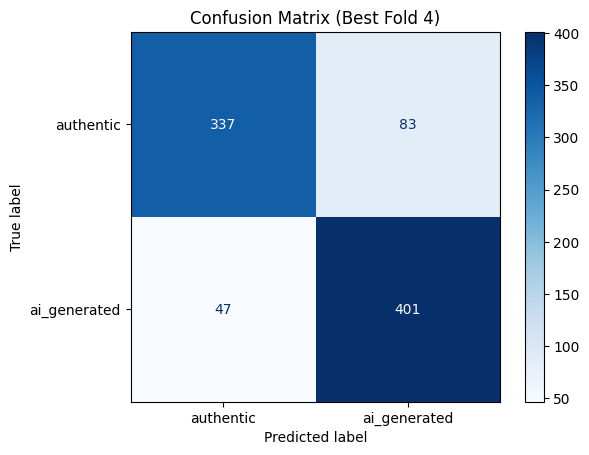

              precision    recall  f1-score   support

   authentic       0.88      0.80      0.84       420
ai_generated       0.83      0.90      0.86       448

    accuracy                           0.85       868
   macro avg       0.85      0.85      0.85       868
weighted avg       0.85      0.85      0.85       868



In [26]:
cm = confusion_matrix(best_fold_labels, best_fold_preds)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["authentic", "ai_generated"]
)

disp.plot(cmap="Blues")
plt.title(f"Confusion Matrix (Best Fold {best_fold_id})")
plt.show()

print(classification_report(
    best_fold_labels,
    best_fold_preds,
    target_names=["authentic", "ai_generated"]
))

## 12. History dataframe

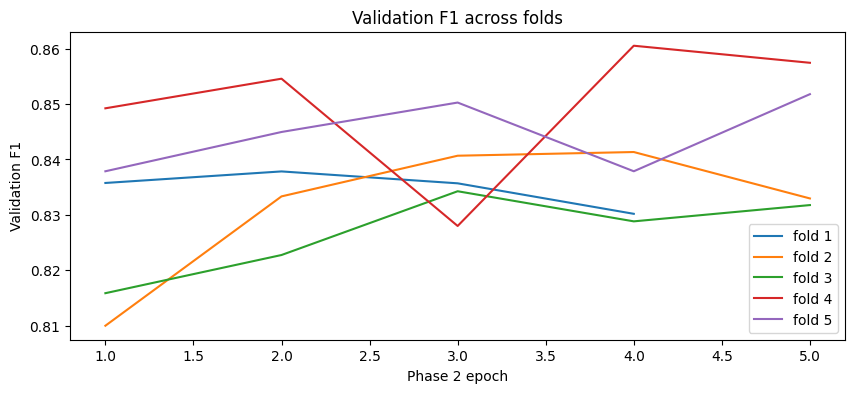

In [27]:
history_df = pd.DataFrame(all_histories)
history_df.head()

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
for fold_id in sorted(history_df["fold"].unique()):
    fold_hist = history_df[(history_df["fold"] == fold_id) & (history_df["phase"] == 2)]
    plt.plot(fold_hist["epoch"], fold_hist["val_f1"], label=f"fold {fold_id}")

plt.xlabel("Phase 2 epoch")
plt.ylabel("Validation F1")
plt.title("Validation F1 across folds")
plt.legend()
plt.show()

## 13. Threshold Tuning 

Best OOF threshold: 0.53
Best OOF threshold F1: 0.8477331052181352


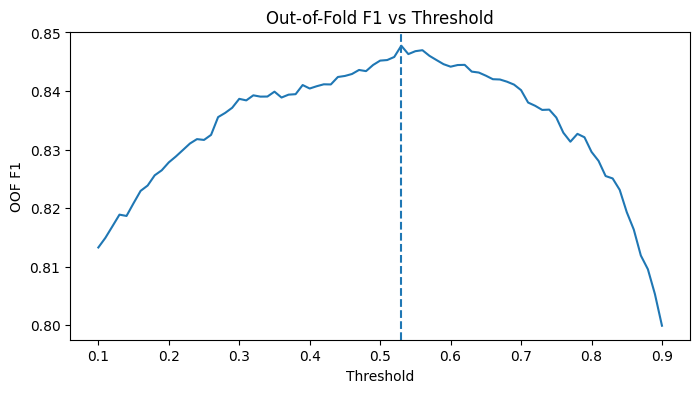

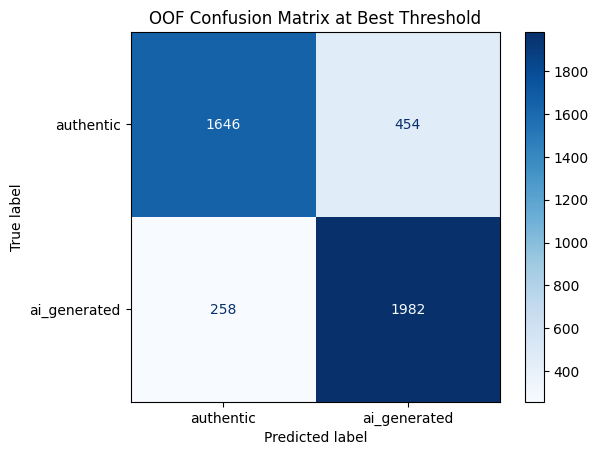

              precision    recall  f1-score   support

   authentic       0.86      0.78      0.82      2100
ai_generated       0.81      0.88      0.85      2240

    accuracy                           0.84      4340
   macro avg       0.84      0.83      0.83      4340
weighted avg       0.84      0.84      0.84      4340



In [28]:

thresholds = np.linspace(0.1, 0.9, 81)
best_thresh = 0.5
best_thresh_f1 = -1
threshold_results = []

for t in thresholds:
    preds = (oof_probs >= t).astype(int)
    f1 = f1_score(oof_true, preds)
    threshold_results.append((t, f1))

    if f1 > best_thresh_f1:
        best_thresh_f1 = f1
        best_thresh = t

print("Best OOF threshold:", best_thresh)
print("Best OOF threshold F1:", best_thresh_f1) # to be used for final test predictions


# plot threshold vs F1
threshold_df = pd.DataFrame(threshold_results, columns=["threshold", "f1"])

plt.figure(figsize=(8, 4))
plt.plot(threshold_df["threshold"], threshold_df["f1"])
plt.axvline(best_thresh, linestyle="--")
plt.xlabel("Threshold")
plt.ylabel("OOF F1")
plt.title("Out-of-Fold F1 vs Threshold")
plt.show()


# confusion matrix at best threshold
oof_preds_best = (oof_probs >= best_thresh).astype(int)

cm = confusion_matrix(oof_true, oof_preds_best)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["authentic", "ai_generated"]
)
disp.plot(cmap="Blues")
plt.title("OOF Confusion Matrix at Best Threshold")
plt.show()

print(classification_report(
    oof_true,
    oof_preds_best,
    target_names=["authentic", "ai_generated"]
))

## 14. Predict probabilities on test set

In [29]:
def predict_test(model, loader, device):
    model.eval()

    image_ids = []
    probs = []

    with torch.no_grad():
        for images, batch_ids in tqdm(loader, desc="Predicting test"):
            images = images.to(device, non_blocking=True)

            outputs = model(images)
            batch_probs = torch.softmax(outputs, dim=1)[:, 1]  # probability of ai_generated

            probs.extend(batch_probs.cpu().numpy())
            image_ids.extend(batch_ids)

    return pd.DataFrame({
        "image_id": image_ids,
        "ai_generated_proba": probs,
    })


test_dataset = EtsyImageDataset(test_df, DATA_DIR, transform=val_transform, is_test=True)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

test_pred_df = predict_test(best_fold_model, test_loader, DEVICE)

test_pred_df["pred_label_id"] = (test_pred_df["ai_generated_proba"] >= best_thresh).astype(int)
test_pred_df["ground_truth"] = test_pred_df["pred_label_id"]

submission_df = test_pred_df[["image_id", "ground_truth"]].copy()
submission_df.to_csv("submission_resnet50_oof_threshold.csv", index=False)

submission_df.head()

Predicting test: 100%|██████████| 59/59 [00:06<00:00,  9.51it/s]


,image_id,ground_truth
0,3ecf1af5-6a8f-416a-9b4c-df9f2e0a0a80.jpg,0
1,2789b3fe-a337-4dc2-b42c-8bccde1f68fb.jpg,0
2,01a342c6-c3fc-4b55-8c22-13c1a556ba87.jpg,0
3,6dcd4df6-7447-4bcf-a29b-f7f53b4c3ed4.jpg,0
4,73b2089b-34a5-49de-a98b-2325512322f1.jpg,1


In [30]:
def load_fold_model(model_path):
    model = build_model()
    model.load_state_dict(torch.load(model_path, map_location=DEVICE))
    model.eval()
    return model


fold_test_preds = []

for fold_id in range(1, NB_SPLITS + 1):
    print(f"\nLoading fold {fold_id} model...")
    model = load_fold_model(f"best_resnet50_fold{fold_id}.pt")

    fold_pred_df = predict_test(model, test_loader, DEVICE)
    fold_pred_df = fold_pred_df.rename(columns={
        "ai_generated_proba": f"fold_{fold_id}_proba"
    })

    fold_test_preds.append(fold_pred_df)

# Merge all fold predictions on image_id
ensemble_df = fold_test_preds[0].copy()

for df in fold_test_preds[1:]:
    ensemble_df = ensemble_df.merge(df, on="image_id", how="inner")

# Average probabilities across folds
proba_cols = [f"fold_{fold_id}_proba" for fold_id in range(1, NB_SPLITS + 1)]
ensemble_df["ai_generated_proba"] = ensemble_df[proba_cols].mean(axis=1)

# Apply tuned threshold
ensemble_df["pred_label_id"] = (ensemble_df["ai_generated_proba"] >= best_thresh).astype(int)

# Map numeric predictions back to competition labels
ensemble_df["ground_truth"] = ensemble_df["pred_label_id"]

# Save submission
submission_df = ensemble_df[["image_id", "ground_truth"]].copy()
submission_df.to_csv("submission_resnet50_fold_ensemble.csv", index=False)

print("Saved submission_resnet50_fold_ensemble.csv")
submission_df.head()


Loading fold 1 model...


Predicting test: 100%|██████████| 59/59 [00:05<00:00, 10.11it/s]



Loading fold 2 model...


Predicting test: 100%|██████████| 59/59 [00:05<00:00, 10.18it/s]



Loading fold 3 model...


Predicting test: 100%|██████████| 59/59 [00:05<00:00, 10.17it/s]


... (2 outputs left out)


Loading fold 5 model...


Predicting test: 100%|██████████| 59/59 [00:05<00:00, 10.62it/s]

Saved submission_resnet50_fold_ensemble.csv


,image_id,ground_truth
0,3ecf1af5-6a8f-416a-9b4c-df9f2e0a0a80.jpg,0
1,2789b3fe-a337-4dc2-b42c-8bccde1f68fb.jpg,0
2,01a342c6-c3fc-4b55-8c22-13c1a556ba87.jpg,0
3,6dcd4df6-7447-4bcf-a29b-f7f53b4c3ed4.jpg,0
4,73b2089b-34a5-49de-a98b-2325512322f1.jpg,0


## 15. Convert probabilities to labels

In [31]:
threshold = 0.5 # can be tuned based on validation set performance

test_pred_df["pred_label_id"] = (test_pred_df["ai_generated_proba"] >= threshold).astype(int)
test_pred_df["ground_truth"] = test_pred_df["pred_label_id"]
# test_pred_df["ground_truth"] = test_pred_df["pred_label_id"].map(id2label)
test_pred_df.head()

,image_id,ai_generated_proba,pred_label_id,ground_truth
0,3ecf1af5-6a8f-416a-9b4c-df9f2e0a0a80.jpg,0.189997,0,0
1,2789b3fe-a337-4dc2-b42c-8bccde1f68fb.jpg,0.000075,0,0
2,01a342c6-c3fc-4b55-8c22-13c1a556ba87.jpg,0.223853,0,0
3,6dcd4df6-7447-4bcf-a29b-f7f53b4c3ed4.jpg,0.012733,0,0
4,73b2089b-34a5-49de-a98b-2325512322f1.jpg,0.704213,1,1


## 17. Create submission CSV

In [32]:
test_pred_df = predict_test(best_fold_model, test_loader, DEVICE)

test_pred_df["pred_label_id"] = (test_pred_df["ai_generated_proba"] >= best_thresh).astype(int)
test_pred_df["ground_truth"] = test_pred_df["pred_label_id"]

submission_df = test_pred_df[["image_id", "ground_truth"]].copy()
submission_df.to_csv("submission_resnet50_oof_threshold.csv", index=False)

submission_df.head()

Predicting test: 100%|██████████| 59/59 [00:05<00:00, 10.15it/s]


,image_id,ground_truth
0,3ecf1af5-6a8f-416a-9b4c-df9f2e0a0a80.jpg,0
1,2789b3fe-a337-4dc2-b42c-8bccde1f68fb.jpg,0
2,01a342c6-c3fc-4b55-8c22-13c1a556ba87.jpg,0
3,6dcd4df6-7447-4bcf-a29b-f7f53b4c3ed4.jpg,0
4,73b2089b-34a5-49de-a98b-2325512322f1.jpg,1
